COU 07506 – Digital Signal Processing (DSP)
Week 05: Lab 2 — Implementing the FFT
 Week 05:
Name: SALIMIN BURUHANI SHECHONGE
Registration No.: 240242411437
Class: BEng24coe-2
Group: 1
Date: 25/11/2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 5.1 — DFT by matrix

In [2]:
def dft_matrix(N):
    n = np.arange(N)
    return np.exp(-2j*np.pi*np.outer(n, n)/N)     # W_N^(nk) matrix

x = np.array([0, 1, 2, 3])
X = dft_matrix(4) @ x
print(np.round(X, 4))                              # expect [6, -2+2j, -2, -2-2j]
print(np.allclose(X, np.fft.fft(x)))
x_back = (dft_matrix(4).conj() @ X) / 4            # IDFT
print(np.round(x_back.real, 6))

# Pre-lab (a) check
xp = np.array([1, 0, -1, 0])
print("pre-lab (a):", np.round(dft_matrix(4) @ xp, 4))

[ 6.+0.j -2.+2.j -2.-0.j -2.-2.j]
True
[0. 1. 2. 3.]
pre-lab (a): [0.+0.j 2.+0.j 0.-0.j 2.+0.j]


## Task 5.2 — Bit reversal

In [3]:
def bit_reverse_indices(N):
    bits = int(np.log2(N))                                   # number of bits, e.g. 3 for N = 8
    return np.array([int(format(i, f"0{bits}b")[::-1], 2) for i in range(N)])

print(bit_reverse_indices(8))        # expect [0 4 2 6 1 5 3 7]

[0 4 2 6 1 5 3 7]


In [4]:
print(bit_reverse_indices(16))
idx = bit_reverse_indices(8)
print("reversing twice gives the original order:", np.array_equal(idx[idx], np.arange(8)))

[ 0  8  4 12  2 10  6 14  1  9  5 13  3 11  7 15]
reversing twice gives the original order: True


## Task 5.3 — Iterative radix-2 FFT

In [5]:
def fft_iterative(x):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    X = x[bit_reverse_indices(N)].copy()           # stage 0: reorder
    size = 2
    while size <= N:                               # stages: 2-, 4-, 8-point ...
        half = size // 2
        W = np.exp(-2j*np.pi*np.arange(half)/size) # twiddle factors
        for start in range(0, N, size):
            top = X[start:start+half].copy()
            bot = X[start+half:start+size] * W
            X[start:start+half] = top + bot        # butterfly upper output
            X[start+half:start+size] = top - bot   # butterfly lower output
        size *= 2
    return X

x = np.random.randn(1024)
print(np.allclose(fft_iterative(x), np.fft.fft(x)))

True


In [6]:
def fft_iterative_verbose(x):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    X = x[bit_reverse_indices(N)].copy()
    print("after bit reversal:", np.round(X, 4))
    size = 2
    stage = 1
    while size <= N:
        half = size // 2
        W = np.exp(-2j*np.pi*np.arange(half)/size)
        print(f"\nstage {stage} ({size}-point), twiddles W = {np.round(W, 4)}")
        for start in range(0, N, size):
            top = X[start:start+half].copy()
            bot = X[start+half:start+size] * W
            X[start:start+half] = top + bot
            X[start+half:start+size] = top - bot
            print(f"  block starting at {start}: top = {np.round(top, 4)}, "
                  f"bot*W = {np.round(bot, 4)}")
        print("  after stage:", np.round(X, 4))
        size *= 2
        stage += 1
    return X

res = fft_iterative_verbose([0, 1, 2, 3])
print("\nfinal:", np.round(res, 4))

after bit reversal: [0.+0.j 2.+0.j 1.+0.j 3.+0.j]

stage 1 (2-point), twiddles W = [1.+0.j]
  block starting at 0: top = [0.+0.j], bot*W = [2.+0.j]
  block starting at 2: top = [1.+0.j], bot*W = [3.+0.j]
  after stage: [ 2.+0.j -2.+0.j  4.+0.j -2.+0.j]

stage 2 (4-point), twiddles W = [1.+0.j 0.-1.j]
  block starting at 0: top = [ 2.+0.j -2.+0.j], bot*W = [ 4.+0.j -0.+2.j]
  after stage: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]

final: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]


## Task 5.4 — How much faster?

In [7]:
import time

def best_time(f, repeats=3):
    """Smallest time over a few runs (reduces timing noise)."""
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

Ns = 2**np.arange(6, 13)                    # 64, 128, ..., 4096
t_dft, t_fft, t_np = [], [], []
rng = np.random.default_rng(0)

for N in Ns:
    x = rng.standard_normal(N)
    t_dft.append(best_time(lambda: dft_matrix(N) @ x))
    t_fft.append(best_time(lambda: fft_iterative(x)))
    t_np.append(best_time(lambda: np.fft.fft(x)))

print("    N | direct DFT (s) | our FFT (s) | np.fft (s) | DFT/FFT speed-up")
for N, a, b, c in zip(Ns, t_dft, t_fft, t_np):
    print(f"{N:5d} | {a:14.6f} | {b:11.6f} | {c:10.7f} | {a/b:8.1f}x")

    N | direct DFT (s) | our FFT (s) | np.fft (s) | DFT/FFT speed-up
   64 |       0.000448 |    0.000565 |  0.0000165 |      0.8x
  128 |       0.001623 |    0.001090 |  0.0000169 |      1.5x
  256 |       0.006085 |    0.007378 |  0.0000219 |      0.8x
  512 |       0.067431 |    0.010945 |  0.0000334 |      6.2x
 1024 |       0.126627 |    0.009958 |  0.0000426 |     12.7x
 2048 |       0.279081 |    0.018097 |  0.0000796 |     15.4x
 4096 |       1.043794 |    0.043834 |  0.0001253 |     23.8x


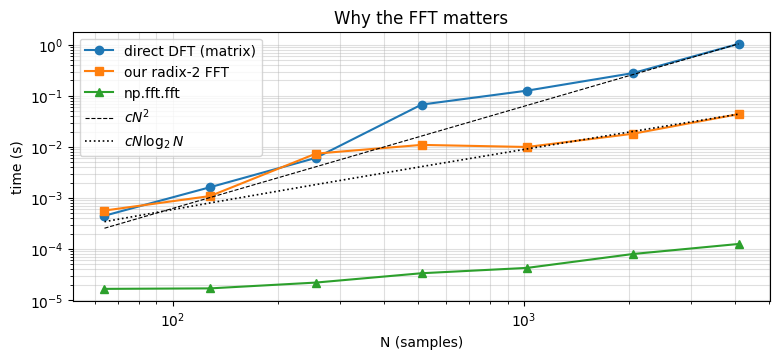

In [8]:
t_dft, t_fft, t_np = map(np.array, (t_dft, t_fft, t_np))

# choose c to match the largest N
c2 = t_dft[-1] / Ns[-1]**2
c1 = t_fft[-1] / (Ns[-1]*np.log2(Ns[-1]))

plt.loglog(Ns, t_dft, "o-", label="direct DFT (matrix)")
plt.loglog(Ns, t_fft, "s-", label="our radix-2 FFT")
plt.loglog(Ns, t_np,  "^-", label="np.fft.fft")
plt.loglog(Ns, c2*Ns**2, "k--", lw=0.8, label=r"$c N^2$")
plt.loglog(Ns, c1*Ns*np.log2(Ns), "k:", lw=1.2, label=r"$c N \log_2 N$")
plt.xlabel("N (samples)"); plt.ylabel("time (s)")
plt.title("Why the FFT matters")
plt.grid(True, which="both", alpha=0.4); plt.legend(); plt.show()

## Task 5.5 — Zero-padding and the DTFT

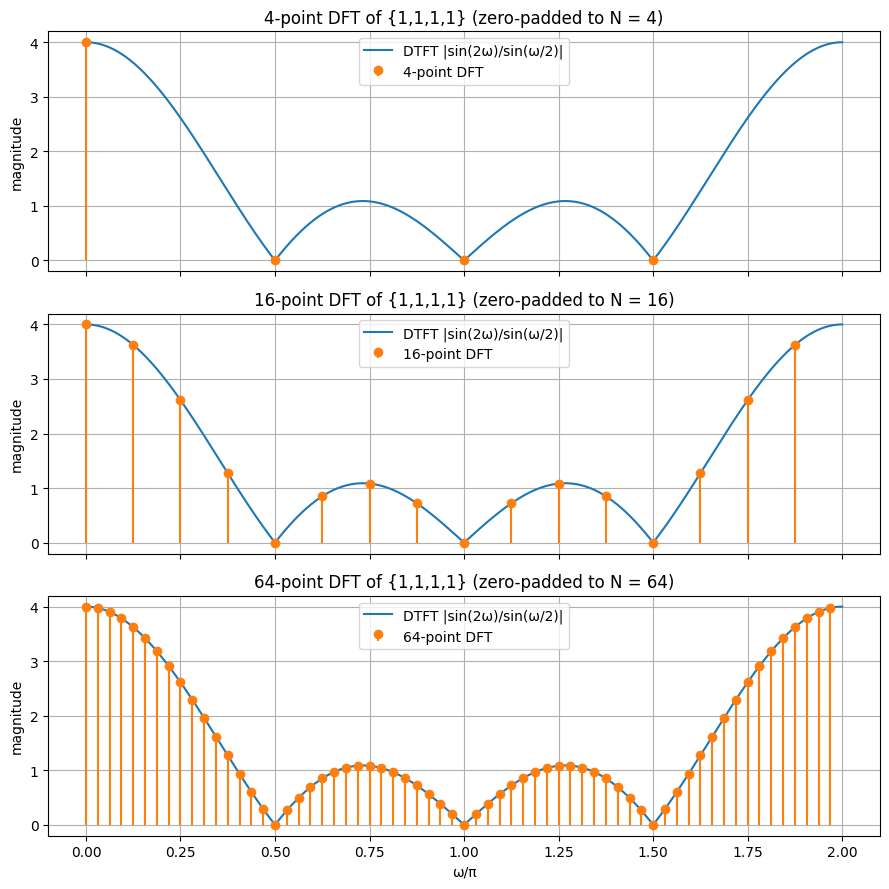

4-point DFT : [4. 0. 0. 0.]


In [9]:
x = np.array([1, 1, 1, 1])

# True DTFT magnitude on a fine grid
w = np.linspace(1e-6, 2*np.pi, 2000)           # avoid w = 0 (0/0)
dtft = np.abs(np.sin(2*w) / np.sin(w/2))
dtft[0] = 4                                    # limit at w = 0

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, N in zip(axes, [4, 16, 64]):
    X = np.fft.fft(x, n=N)                     # zero-pads x to length N
    wk = 2*np.pi*np.arange(N)/N                # DFT frequencies
    ax.plot(w/np.pi, dtft, "C0-", label="DTFT |sin(2ω)/sin(ω/2)|")
    ax.stem(wk/np.pi, np.abs(X), linefmt="C1-", markerfmt="C1o",
            basefmt=" ", label=f"{N}-point DFT")
    ax.set_title(f"{N}-point DFT of {{1,1,1,1}} (zero-padded to N = {N})")
    ax.set_ylabel("magnitude"); ax.grid(True); ax.legend()
axes[-1].set_xlabel("ω/π")
plt.tight_layout(); plt.show()

print("4-point DFT :", np.round(np.abs(np.fft.fft(x, 4)), 3))

## Task 5.6 — Fast convolution


In [10]:
import time

rng = np.random.default_rng(0)
x = rng.standard_normal(10000)              # random signal, L = 10000
h = np.ones(501) / 501                      # 501-tap moving average, M = 501

# (a) direct convolution
t0 = time.perf_counter()
y_direct = np.convolve(x, h)
t_direct = time.perf_counter() - t0

# (b) FFT convolution
L, M = len(x), len(h)
N = 1 << int(np.ceil(np.log2(L + M - 1)))   # next power of two >= L + M - 1
t0 = time.perf_counter()
Xf = np.fft.fft(x, n=N)                     # zero-pads x to N
Hf = np.fft.fft(h, n=N)                     # zero-pads h to N
y_fft = np.fft.ifft(Xf * Hf).real[:L + M - 1]
t_fft = time.perf_counter() - t0

print("L + M - 1 =", L + M - 1, " N =", N)
print("results agree:", np.allclose(y_direct, y_fft))
print("max difference:", np.max(np.abs(y_direct - y_fft)))
print(f"np.convolve : {t_direct*1e3:.2f} ms")
print(f"FFT method  : {t_fft*1e3:.2f} ms")

L + M - 1 = 10500  N = 16384
results agree: True
max difference: 6.938893903907228e-17
np.convolve : 3.94 ms
FFT method  : 8.64 ms


In [11]:
a = np.array([2, 1.5, 1, 0.5])
b = np.array([1, 0, 1, 0])

c = np.fft.ifft(np.fft.fft(a) * np.fft.fft(b)).real
print("circular convolution:", np.round(c, 4))        # expect [3 2 3 2]

circular convolution: [3. 2. 3. 2.]
